# DME channel: benchmarking three implementations

Density matrix exponentiation (DME) is the subroutine that DBAC uses to turn a copy of a
quantum state $\rho$ ("instruction") into an approximation of the unitary $e^{-it\rho}$,
applied to another register $\sigma$ ("data"), **without ever synthesizing $e^{-it\rho}$
as a gate**. Concretely, the DME channel is

$$
\hat{E}_t^{(\rho)}(\sigma) = \mathrm{Tr}_{1}\Big[e^{-i t\,\mathrm{SWAP}}\,(\rho\otimes\sigma)\,e^{i t\,\mathrm{SWAP}}\Big],
$$

i.e. a partial SWAP between $\rho$ and $\sigma$ followed by discarding the instruction
register. Trotterizing this SWAP into $M$ small steps and repeating it gives a channel
that converges to the exact evolution $e^{-it\rho}\sigma e^{it\rho}$ as $M\to\infty$; this
Trotterized channel is the building block of every DB-QITE/DBAC recursion step used
elsewhere in this repository.

This notebook benchmarks three equivalent ways of computing the DME channel
(`functions/dme.py`) against the exact evolution, for a random data/instruction pair:

- **DME channel**: explicit SWAP evolution + numpy partial trace (`dme_channel`).
- **Equivalent channel**: the same channel, written analytically with cos/sin so it
  needs no partial trace (`dme_channel_equivalent`) -- useful because it is much faster.
- **Qibo**: the same SWAP evolution built from a `qibo` circuit (`dme_qibo`), closer to
  how it would run on hardware.

All of the computation lives in [`scripts/dme_channel.py`](../scripts/dme_channel.py);
this notebook just calls it and plots the result with
[`visualization/dme_plots.py`](../visualization/dme_plots.py).

In [1]:
%matplotlib inline
import sys
sys.path.append('..')

from visualization import use_paper_style
from scripts.dme_channel import run_dme_channel_benchmark

use_paper_style(font_size=16, figsize=(5, 3.5))

## Running the benchmark

For an increasing number of Trotter steps $M$, we compute $\lVert e^{-it\rho}\sigma e^{it\rho} - \hat{E}_t^{(\rho)}(\sigma)\rVert$
for each implementation. The error should shrink roughly like $1/M$ as the Trotterized
SWAP evolution approaches the exact one.

In [2]:
norms = run_dme_channel_benchmark(t=1.0, max_M=50, seed=0)
list(norms.keys())

[Qibo 0.3.5|INFO|2026-10-12 12:55:49]: Using numpy backend on /CPU:0


['DME channel', 'Equivalent channel', 'Qibo']

## The paper figure

The curve below (DME channel only) is the one saved to
`plots/DME_norm.pdf` and used in the paper.

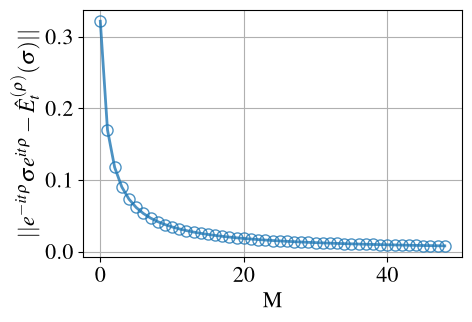

In [3]:
from visualization import plot_dme_channel_norms

plot_dme_channel_norms({"DME channel": norms["DME channel"]});

## All three implementations side by side, with their final-$M$ error annotated:

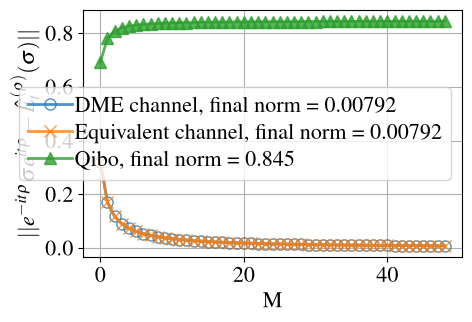

In [4]:
plot_dme_channel_norms(norms, show_final_value=True);

---
To regenerate all the figures in `plots/` from the command line instead of this notebook, run:

```bash
python scripts/dme_channel.py
```